<a href="https://colab.research.google.com/github/eojin22/ESAA/blob/main/OB_WEEK11_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 7. 시계열 분석

## **7.1 시계열 문제**
**시계열 분석(Time Series Analysis):** 시간에 따라 변하는 데이터를 사용하여 추이를 분석하는 것

추세를 파악하거나 향후 전망 등을 예측하기 위한 용도로 시계열 분석 사용

> 시계열 형태
- 불규칙 변동: 일정한 규칙성이 없어 예측하기 어렵고 우연적으로 발생하는 변동 (전쟁, 홍수, 지진 등)
- 추세 변동: 시계열 자료가 갖는 장기적인 변화 추세 (GDP, 인구 증가 등)
- 순환 변동: 경기 변동처럼 수년에 걸쳐 반복적으로 나타나는 변동 (주기가 반드시 일정한 것은 아님)
- 계절 변동: 계절적 영향과 사회적 관습에 따라 일정한 주기로 발생하는 변동 (여름철 아이스크림 판매량 증가 등)

> 시계열 데이터 유형
- 규칙적 시계열: 트렌드와 분산이 불변하는 데이터
- 불규칙적 시계: 트렌드 혹은 분산이 변화하는 시계열 데이터

불규칙적 시계열을 분석하기 위해 차분 등의 방법을 사용하며, 대표적인 시계열 분석 모델에는 AR, MA, ARMA, ARIMA가 있음

## **7.2 AR, MA, ARMA, ARIMA**
시계열 분석은 과거의 관측값과 시간에 따른 변화 패턴을 이용해 미래의 값을 예측한다는 특징이 있음

### **7.2.1 AR 모델**
**AR(AutoRegressive, 자기 회귀) 모델**: 이전 관측값이 현재 관측값에 영향을 준다는 아이디어에 기반한 모델

과거 시점의 데이터를 이용하여 현재 시점의 데이터를 예측



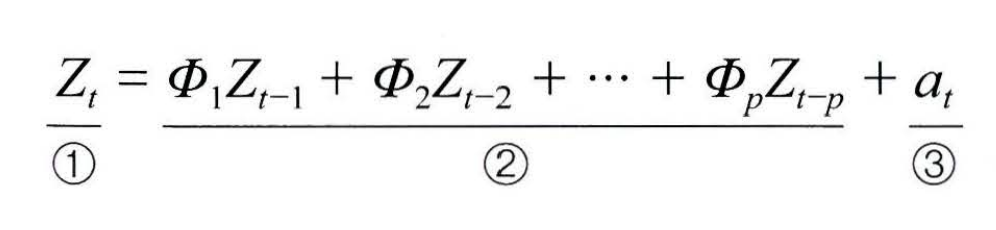

1. 시계열 데이터에서 현재 시점
2. 과거가 현재에 미치는 영향을 나타내는 모수(Ø)에 시계열 데이터의 과거 시점을 곱한 것
3. 시계열 분석에서 오차 항을 의미하며 백색 잡음이라고도 함

수식은 p 시점을 기준으로 그 이전의 데이터에 의해 현재 시점의 데이터가 영향을 받는 모형이라고 할 수 있음

### **7.2.2 MA 모델**
**MA(이동 평균) 모델**: 트렌드가 변화하는 상황에 적합한 회귀 모델
시계열을 따라 윈도우 크기만큼 슬라이딩된다고 해서 이동 평균 모델이라고 함




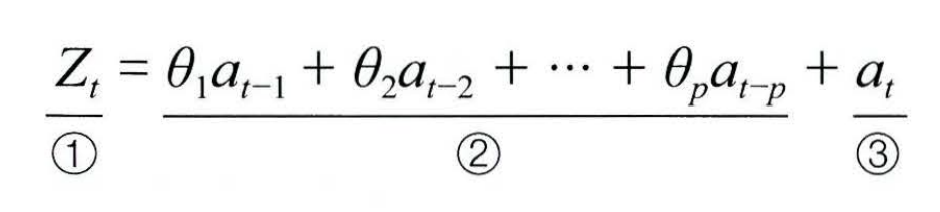

1. 시계열 데이터에서 현재 시점
2. 매개변수(θ)에 과거 시점의 오차를 곱한 것
3. 오차 항

수식은 현재 데이터의 상태를 추론하는 것이 아닌, 이전 데이터의 오차에서 현재 데이터의 상태를 추론

### **7.2.3 ARMA 모델**
**ARMA(AutoRegressive Moving Average, 자기 회귀 이동 평균) 모델**: AR 모델과 MA 모델을 결합한 모델

과거의 관측값과 과거의 오차를 모두 고려하여 현재 데이터를 예측

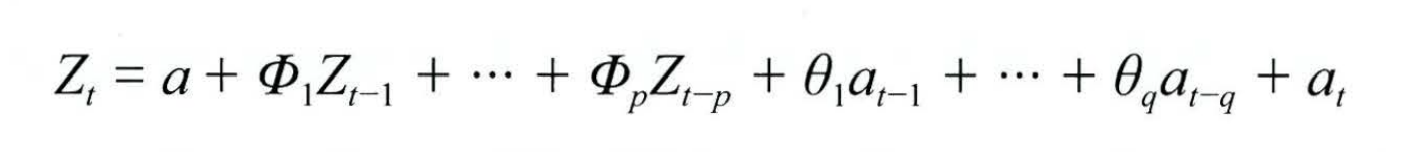

- **AR**: 과거 데이터의 값 이용
- **MA**: 과거 데이터의 오차 이용
- **ARMA**: 과거 데이터의 값과 오차를 함께 이용

주로 정상성을 가진 시계열 데이터를 분석하는 데 사용


### **7.2.4 ARIMA 모델**

**ARIMA(AutoRegressive Integrated Moving Average, 자기 회귀 누적 이동 평균) 모델**: 자기 회귀와 이동 평균을 둘 다 고려하는 모형인데, ARMA와 달리 과거 데이터의 선형 관계뿐만 아니라 추세까지 고려한 모델


> statsmodels 라이브러리를 이용한 ARIMA 구현 절차

1. ARIMA() 함수를 호출하여 사용, ARIMA(p, d, q)
- p: 자기 회귀 차수
- d: 차분 차수
- q: 이동 평균 차수
2. fit() 메서드를 호출하고 모델에 데이터를 적용해 훈련시킴
3. predict() 메서드를 호출해 미래의 추세 및 동향에 대해 예측

In [1]:
!pip install statsmodels

In [2]:
!git clone https://github.com/gilbutITbook/080289.git

Cloning into '080289'...
remote: Enumerating objects: 2278, done.
remote: Counting objects: 100% (16/16), done.
remote: Compressing objects: 100% (14/14), done.
remote: Total 2278 (delta 3), reused 2 (delta 2), pack-reused 2262 (from 2)
Receiving objects: 100% (2278/2278), 330.29 MiB | 22.05 MiB/s, done.
Resolving deltas: 100% (13/13), done.
Updating files: 100% (2591/2591), done.


/tmp/ipykernel_160/1480756572.py:10: FutureWarning: The argument 'date_parser' is deprecated and will be removed in a future version. Please use 'date_format' instead, or read your data in as 'object' dtype and then call 'to_datetime'.
  series = read_csv('/content/080289/chap07/data/sales.csv', header=0, parse_dates=[0],
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


                               SARIMAX Results                                
Dep. Variable:                  Sales   No. Observations:                   36
Model:                 ARIMA(5, 1, 0)   Log Likelihood                -199.651
Date:                Thu, 12 Nov 2026   AIC                            411.302
Time:                        03:26:00   BIC                            420.634
Sample:                    01-01-1991   HQIC                           414.523
                         - 12-01-1993                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.8788      0.227     -3.876      0.000      -1.323      -0.434
ar.L2         -0.2787      0.232     -1.203      0.229      -0.733       0.176
ar.L3         -0.0076      0.270     -0.028      0.9

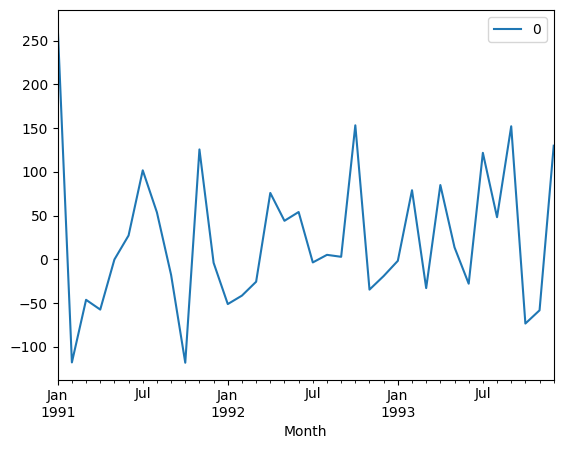

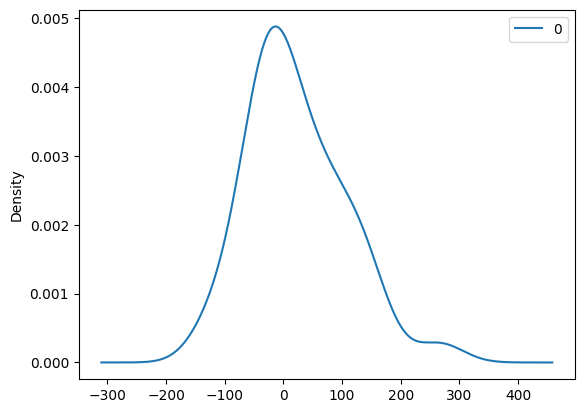

                0
count   36.000000
mean    22.459086
std     82.505331
min   -118.213281
25%    -33.308343
50%      1.361178
75%     76.704967
max    266.000000


In [3]:
from pandas import read_csv
from datetime import datetime
from pandas import DataFrame
from statsmodels.tsa.arima.model import ARIMA
from matplotlib import pyplot

def parser(x):
  return datetime.strptime('199'+x, '%Y-%m')  #strptime()은 날짜와 시간 정보를 문자열로 바꿔주는 메서드

series = read_csv('/content/080289/chap07/data/sales.csv', header=0, parse_dates=[0],
                  index_col=0, date_parser=parser)

model = ARIMA(series, order=(5,1,0))
model_fit = model.fit()
print(model_fit.summary())

residuals = DataFrame(model_fit.resid)
residuals.plot()
pyplot.show()
residuals.plot(kind='kde')
pyplot.show()
print(residuals.describe())

/tmp/ipykernel_160/1291117167.py:11: FutureWarning: The argument 'date_parser' is deprecated and will be removed in a future version. Please use 'date_format' instead, or read your data in as 'object' dtype and then call 'to_datetime'.
  series = read_csv('/content/080289/chap07/data/sales.csv', header=0, parse_dates=[0],


predicted=352.855343, expected=346.300000
predicted=277.398036, expected=329.700000
predicted=368.753734, expected=445.400000
predicted=331.773635, expected=325.900000
predicted=372.070407, expected=449.300000
predicted=360.020872, expected=411.300000
predicted=454.526230, expected=417.400000
predicted=388.690699, expected=545.500000
predicted=437.632447, expected=477.600000
predicted=516.437624, expected=687.000000
predicted=520.916191, expected=435.300000
predicted=675.594647, expected=587.300000
predicted=505.201016, expected=676.900000
Test MSE: 9118.818


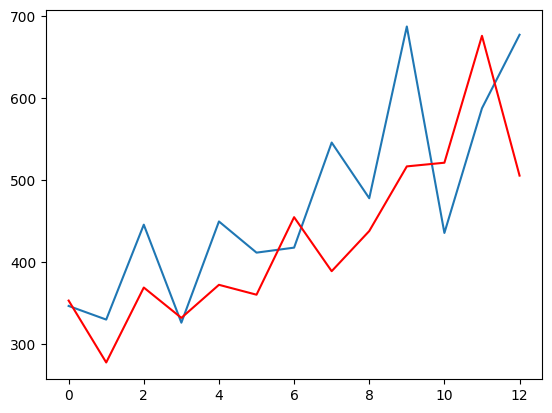

In [4]:
import numpy as np
from pandas import read_csv
from datetime import datetime
from matplotlib import pyplot
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_squared_error

def parser(x):
  return datetime.strptime('199'+x, '%Y-%m')

series = read_csv('/content/080289/chap07/data/sales.csv', header=0, parse_dates=[0],
                  index_col=0, date_parser=parser)

X = series.values.flatten()
X = np.nan_to_num(X)
size = int(len(X)*0.66)
train, test = X[0:size], X[size:len(X)]
history = [x for x in train]
predictions = list()
for t in range(len(test)):
  model = ARIMA(history, order=(5,1,0))
  model_fit = model.fit()
  output = model_fit.forecast()
  yhat = output[0]
  predictions.append(yhat)
  obs = test[t]
  history.append(obs)
  print( 'predicted=%f, expected=%f' % (yhat, obs))
error = mean_squared_error(test, predictions)
print('Test MSE: %.3f' % error)
pyplot.plot(test)
pyplot.plot(predictions, color='red')
pyplot.show()

## **7.3 순환 신경망(RNN)**
**RNN**: 시간적으로 연속성이 있는 데이터를 처리하려고 고안된 인공 신경망

새로운 입력이 네트워크로 들어올 때마다 기억은 조금씩 수정됨, 최종적으로 남겨진 기억은 모든 입력 전체를 요약한 정보가 됨

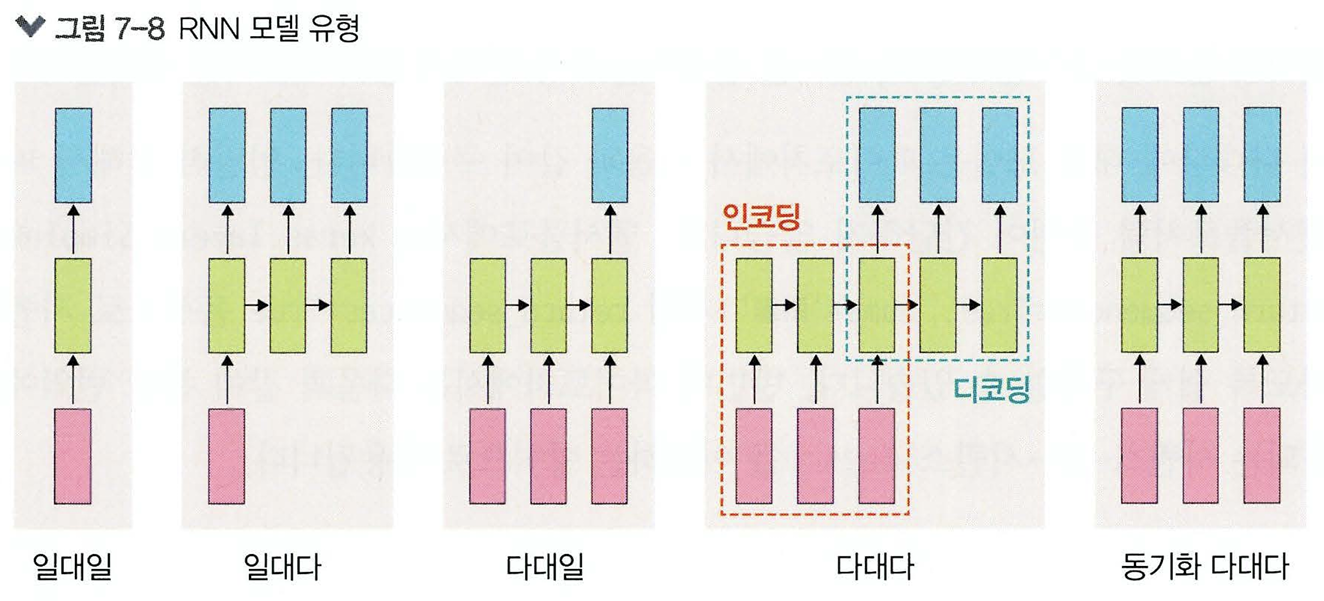

1. 일대일: 순환이 없기 때문에 RNN이라고 말하기 어려우며, 순방향 네트워크가 대표적 사례
2. 일대다: 입력이 하나이고, 출력이 다수인 구조. 이미지를 입력해서 이미지에 대한 설명을 문장으로 출력하는 이미지 캡션(image captioning)이 대표적 사례
3. 다대일: 입력이 다수이고 출력이 하나인 구조, 문장을 입력해 긍/부정을 출력하는 감성 분석기에서 사용
4. 다대다: 입력과 출력이 다수인 구조, 언어를 번역하는 자동 번역기 등이 대표적 사례
5. 동기화 다대다: 다대다의 유형처럼 입력과 출력이 다수인 구조. 문장에서 다음에 나올 단어를 예측하는 언어 모델, 즉 프레임 수준의 비디오 분류가 대표적 사례

### 7.3.1 RNN 계층과 셀
- RNN은 내장된 계층뿐만 아니라 셀 레벨의 API도 제공
- RNN 계층이 입력된 배치 순서대로 모두 처리하는 것과 다르게 RNN 셀은 오직 하나의 단계만 처리
- 따라서 RNN 셀은 RNN 계층의 for loop 구문을 갖는 구조라고 할 수 있음

>셀 유형
- nn. RNNCell: SimpleRNN 계층에 대응되는 RNN 셀
- nn.GRUCell: GRU 계층에 대응되는 GRU 셀
- nn.LSTMCell: LSTM 계층에 대응되는 LSTM 셀

RNN의 계층과 셀을 분리해서 설명하는 이유는 파이토치에서 이 둘을 분리해서 구현이 가능하기 때문